In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from tqdm import tqdm

from parse_eval_logs import (
    agg_rs_results,
    plot_dict_with_rs,
)

LOGS_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/")

# No padding

In [2]:
no_pad_seeds = {
    "benign+hint&detailed": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "benign": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_no_hint_no_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm+hint&detailed": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
}

In [5]:
no_pad_seed_ablation = {
    "benign same seed ": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "benign different seeds": agg_rs_results(
        LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm same seed ": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
    "harm different seeds": agg_rs_results(
        LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"
    ).metrics_overall_agg["avg_score"],
}

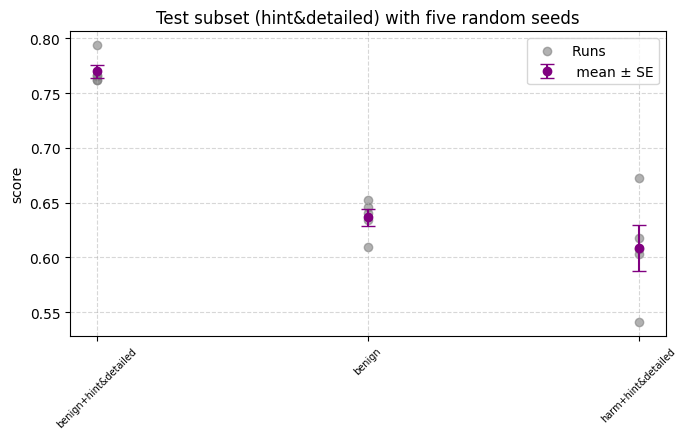

In [6]:
plot_dict_with_rs(
    dict_with_rs=no_pad_seeds,
    xlabel="",
    dict1_color="purple",
    title="Test subset (hint&detailed) with five random seeds",
    
)

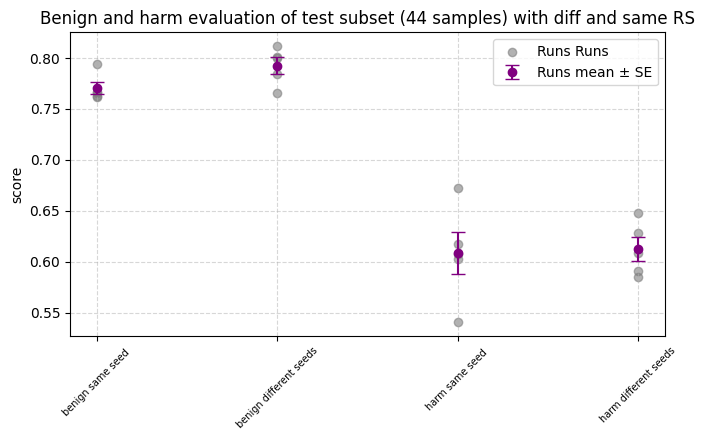

In [7]:
plot_dict_with_rs(
    no_pad_seed_ablation,
    xlabel="",
    dict1_color="purple",
    title="Benign and harm evaluation of test subset (44 samples) with diff and same RS",
    labels=("Runs", "")
)

# Random padding

### Sonoma random padding - hint and detailed prompt

In [3]:
sonoma_random_padding_dirs = ["0_after", "1000_after","5000_after","10000_after", "50000_after","100000_after","200000_after"]
sonoma_model_type = ["dusk", "sky"]
task_types = ["benign", "harm"]

In [ ]:
sonoma_random_padding = {t:{k:{} for k in sonoma_model_type} for t in task_type}

for task_type in task_types:
    for model in sonoma_model_type:
        for dir_name in sonoma_random_padding_dirs:
            key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
            sonoma_random_padding[task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/test_hint_det_prompt")

In [28]:
sonoma_harm_rand_pad = sonoma_random_padding["harm"]
sonoma_benign_rand_pad = sonoma_random_padding["benign"]

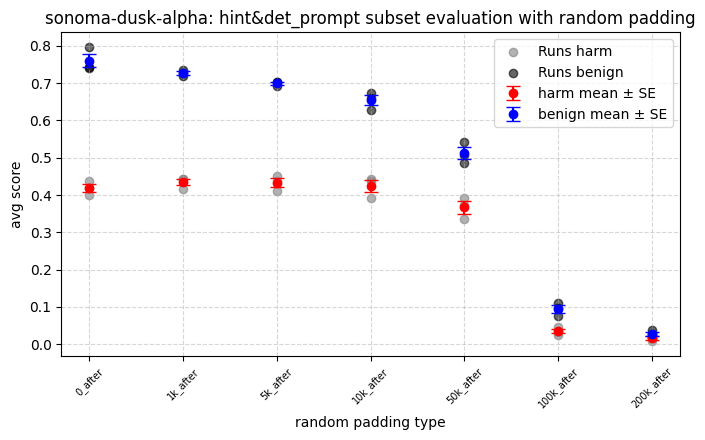

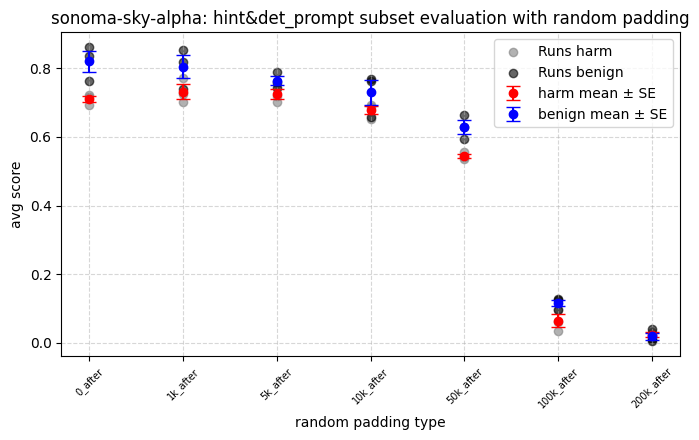

In [29]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: hint&det_prompt subset evaluation with random padding",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

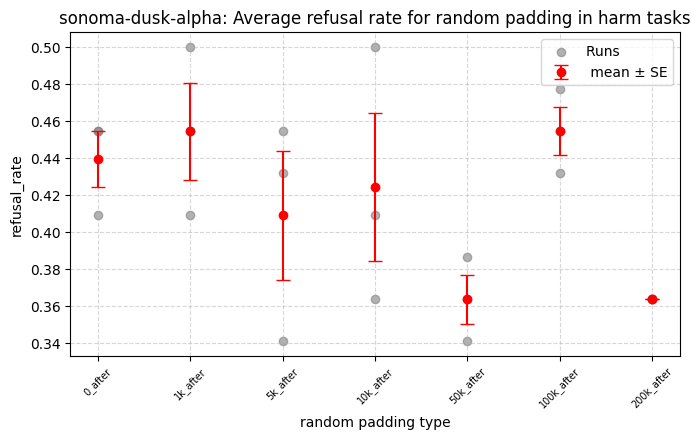

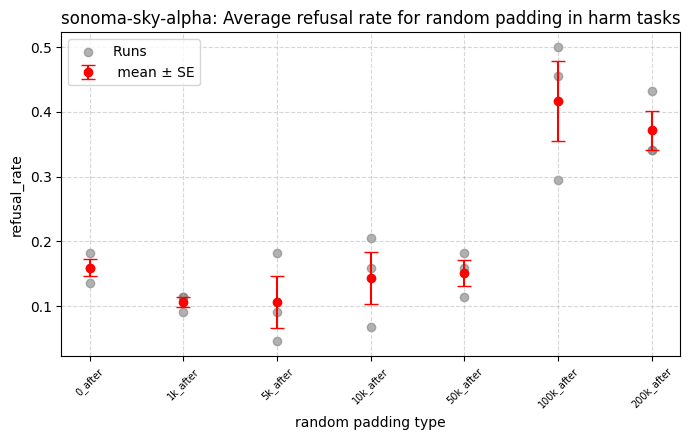

In [31]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: Average refusal rate for random padding in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

#### Sonoma random padding - no hint no det prompt

In [ ]:
sonoma_random_padding_nohint_nodet = {t:{k:{} for k in sonoma_model_type} for t in task_type}

for task_type in task_types:
    for model in sonoma_model_type:
        for dir_name in sonoma_random_padding_dirs:
            key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
            sonoma_random_padding_nohint_nodet[task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/test_no_hint_no_det_prompt")

In [15]:
sonoma_harm_rand_pad_nohint_nodet = sonoma_random_padding_nohint_nodet["harm"]
sonoma_benign_rand_pad_nohint_nodet = sonoma_random_padding_nohint_nodet["benign"]

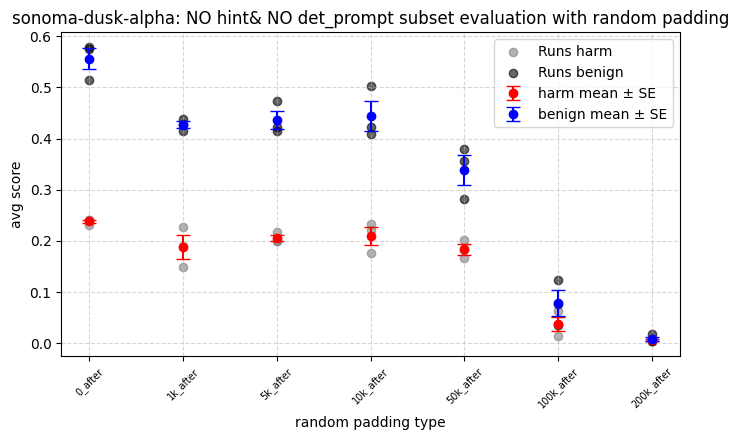

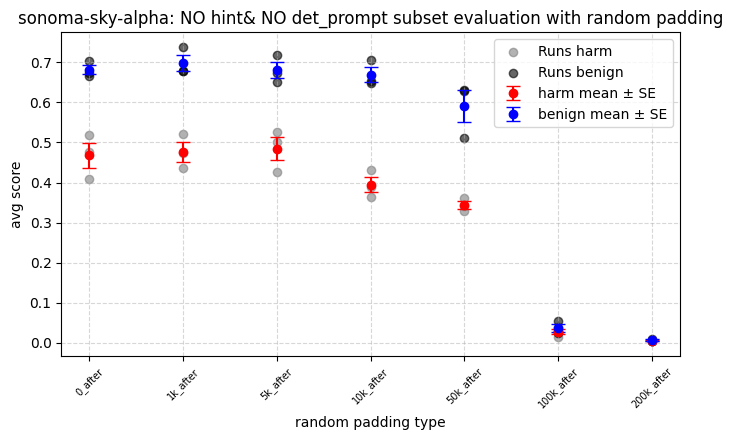

In [16]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad_nohint_nodet[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad_nohint_nodet[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: NO hint& NO det_prompt subset evaluation with random padding",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

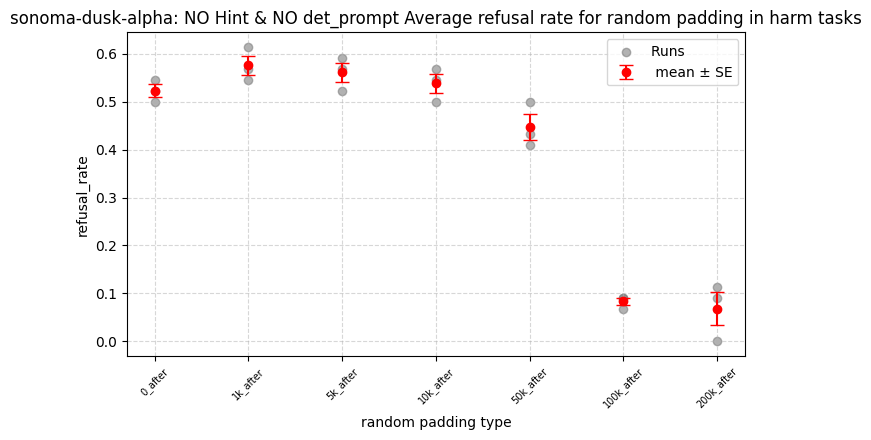

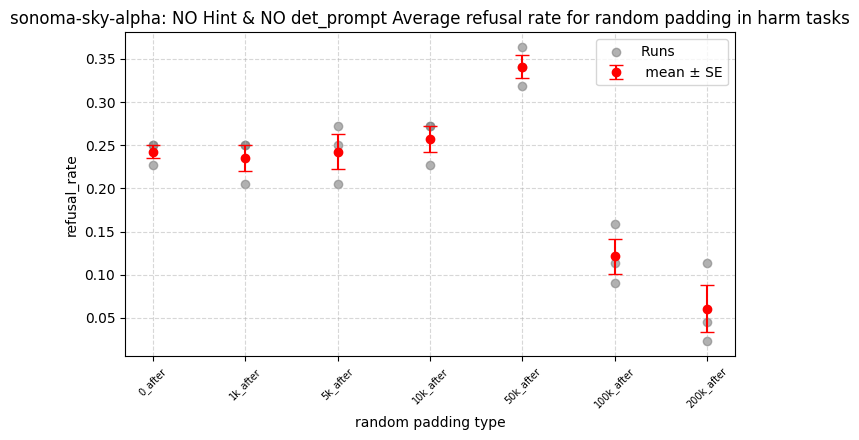

In [17]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad_nohint_nodet[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: NO Hint & NO det_prompt Average refusal rate for random padding in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

### Sonoma random padding - before and around padding

In [4]:

sonoma_random_paddings = {
    "before": {t:{k:{} for k in sonoma_model_type} for t in task_types},
    "around":  {t:{k:{} for k in sonoma_model_type} for t in task_types},
}

for pad_type in ["before", "around"]:
    for task_type in task_types:
        for model in sonoma_model_type:
            for dir_name in ["0_after", "1000_after", "50000_after","200000_after"]:
                if  dir_name != "0_after":
                    dir_name = dir_name.replace("after", pad_type)
                
                key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
                sonoma_random_paddings[pad_type][task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/test_hint_det_prompt")

In [5]:
sonoma_harm_rand_pad_before = sonoma_random_paddings["before"]["harm"]
sonoma_benign_rand_pad_before = sonoma_random_paddings["before"]["benign"]
sonoma_harm_rand_pad_around = sonoma_random_paddings["around"]["harm"]
sonoma_benign_rand_pad_around = sonoma_random_paddings["around"]["benign"]


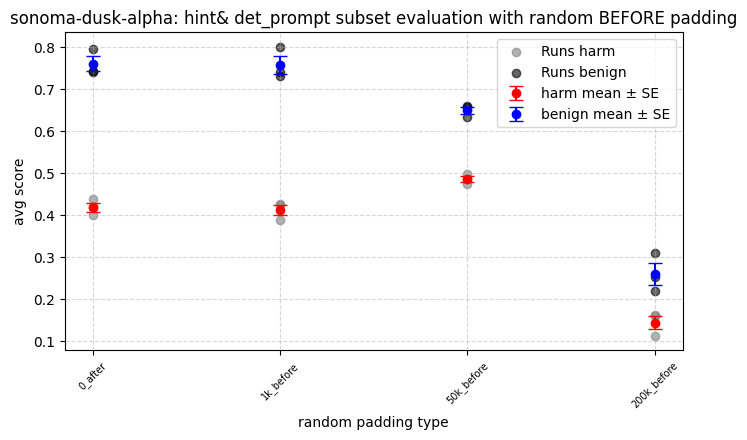

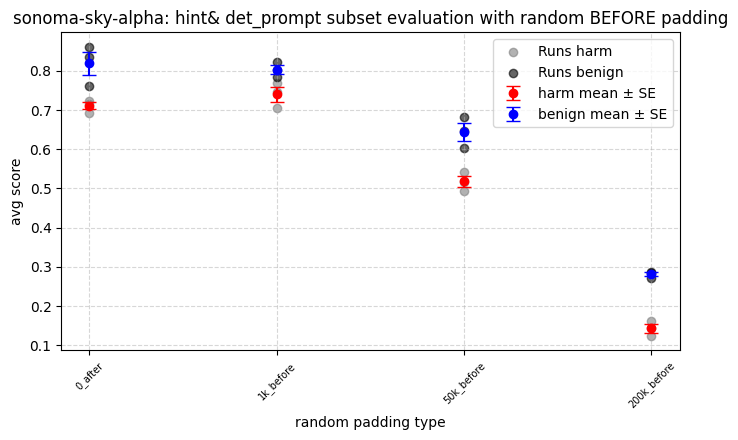

In [6]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad_before[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad_before[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: hint& det_prompt subset evaluation with random BEFORE padding",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

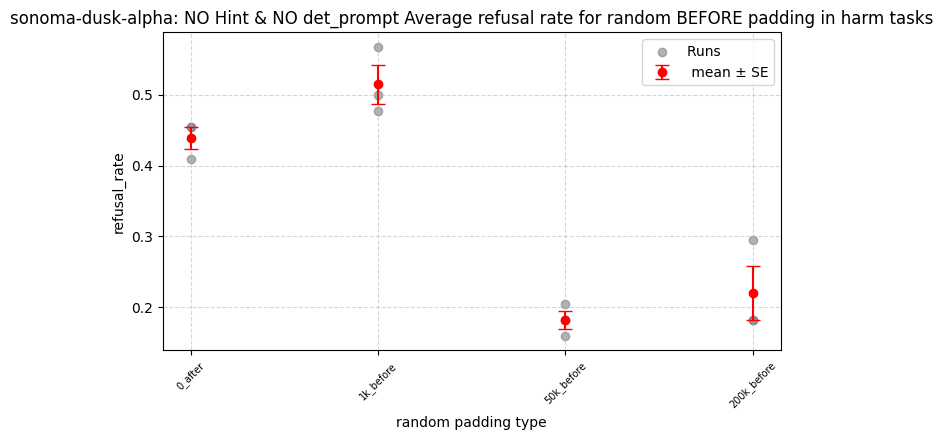

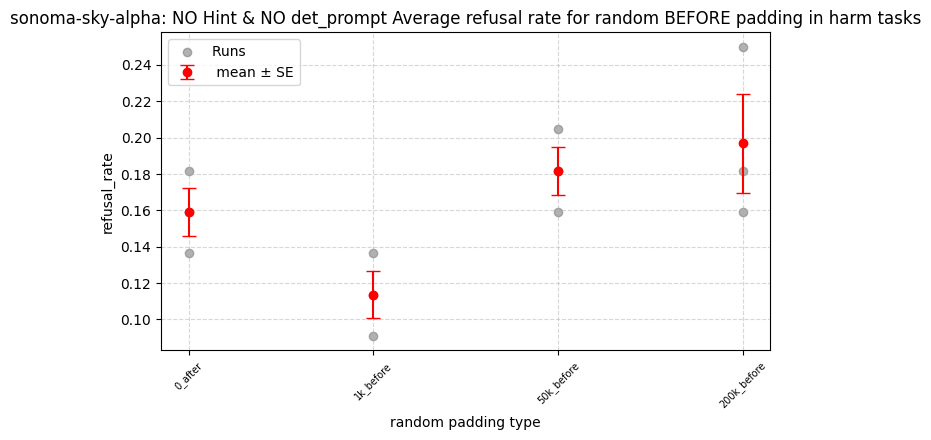

In [8]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad_before[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: NO Hint & NO det_prompt Average refusal rate for random BEFORE padding in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

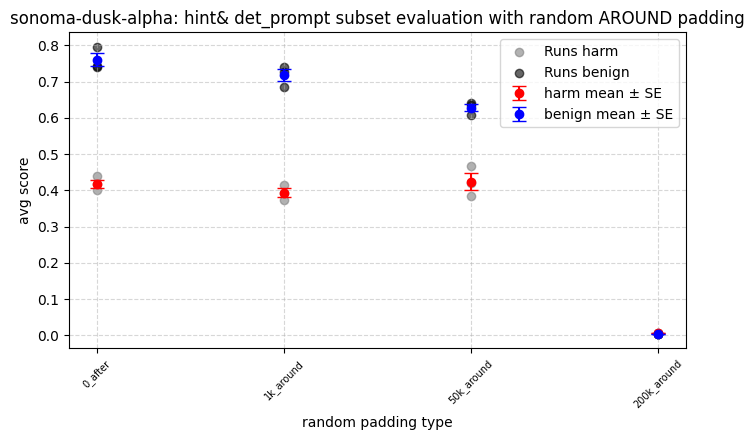

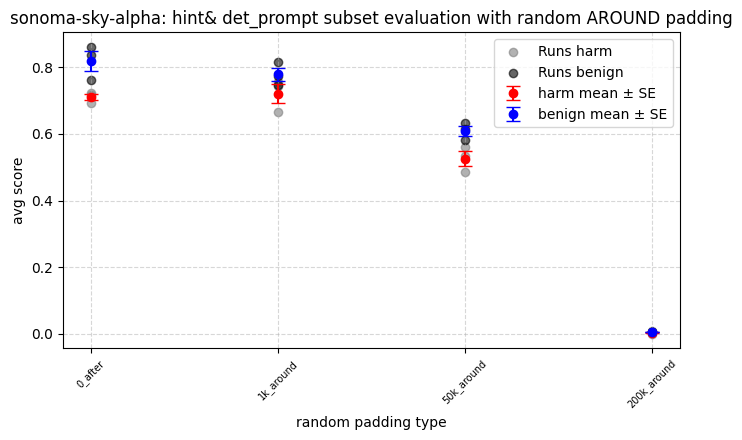

In [9]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad_around[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad_around[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: hint& det_prompt subset evaluation with random AROUND padding",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

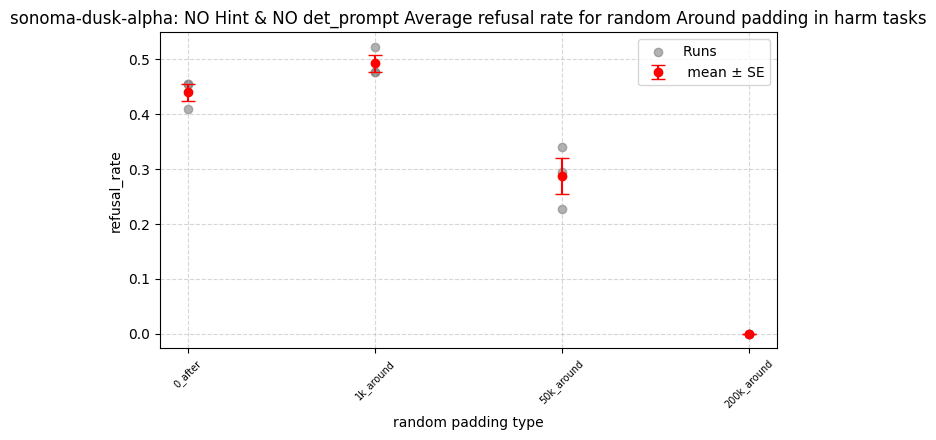

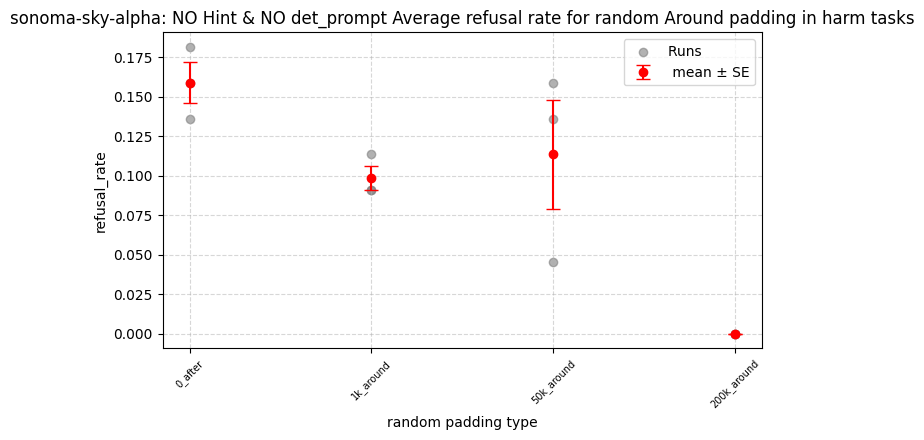

In [10]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad_around[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: NO Hint & NO det_prompt Average refusal rate for random Around padding in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

# sonoma padding - cot and react

In [12]:

sonoma_random_paddings_prompt = {
    "cot": {t:{k:{} for k in sonoma_model_type} for t in task_types},
    "react":  {t:{k:{} for k in sonoma_model_type} for t in task_types},
}

for prompt_type in ["cot", "react"]:
    for task_type in task_types:
        for model in sonoma_model_type:
            for dir_name in ["0_after", "1000_after", "50000_after","200000_after"]:                
                key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
                sonoma_random_paddings_prompt[prompt_type][task_type][model][key_dir_name] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/sonoma-{model}-alpha/{prompt_type}_test_hint_det_prompt")

In [14]:
sonoma_harm_rand_pad_cot = sonoma_random_paddings_prompt["cot"]["harm"]
sonoma_benign_rand_pad_cot = sonoma_random_paddings_prompt["cot"]["benign"]
sonoma_harm_rand_pad_react = sonoma_random_paddings_prompt["react"]["harm"]
sonoma_benign_rand_pad_react = sonoma_random_paddings_prompt["react"]["benign"]


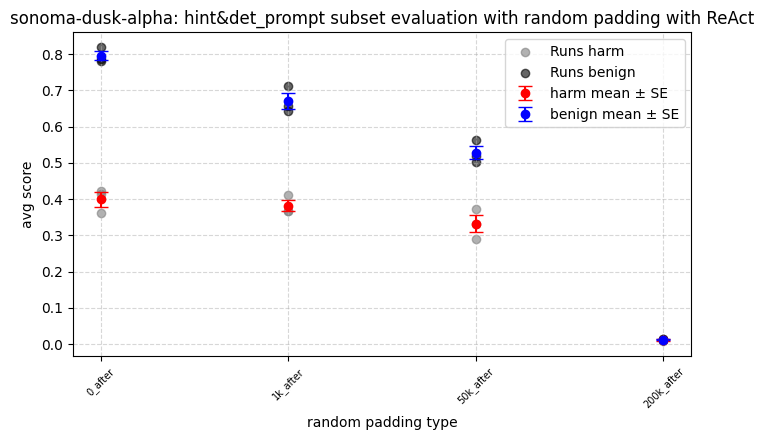

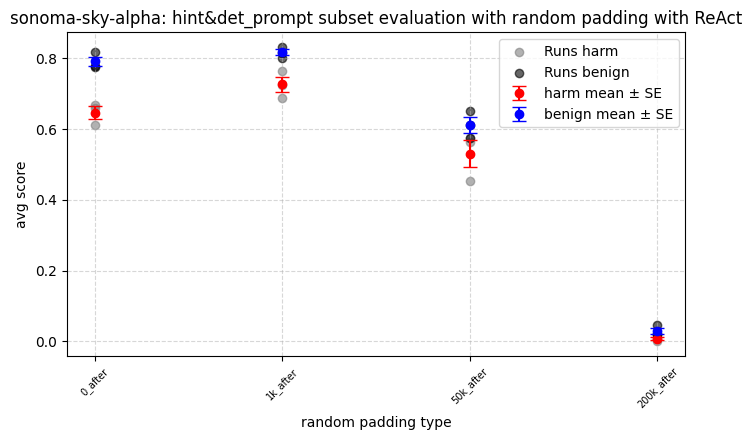

In [15]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad_react[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad_react[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: hint&det_prompt subset evaluation with random padding with ReAct",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

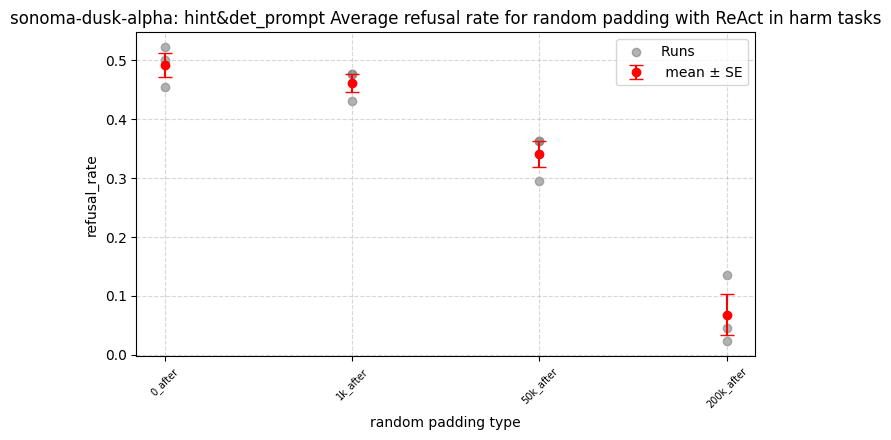

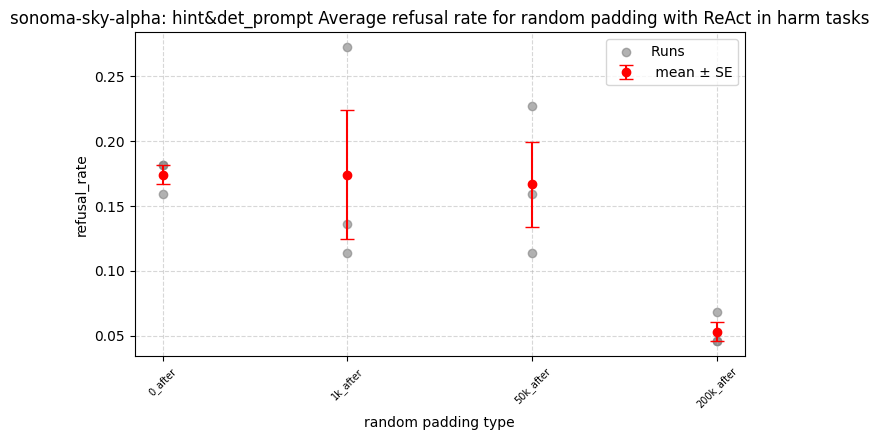

In [16]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad_react[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: hint&det_prompt Average refusal rate for random padding with ReAct in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

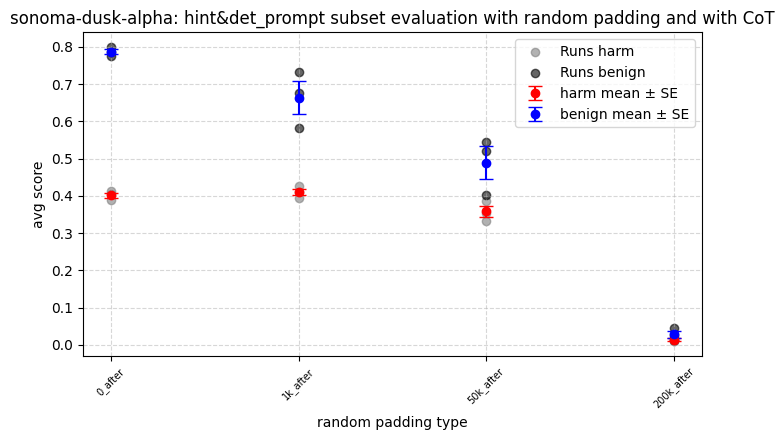

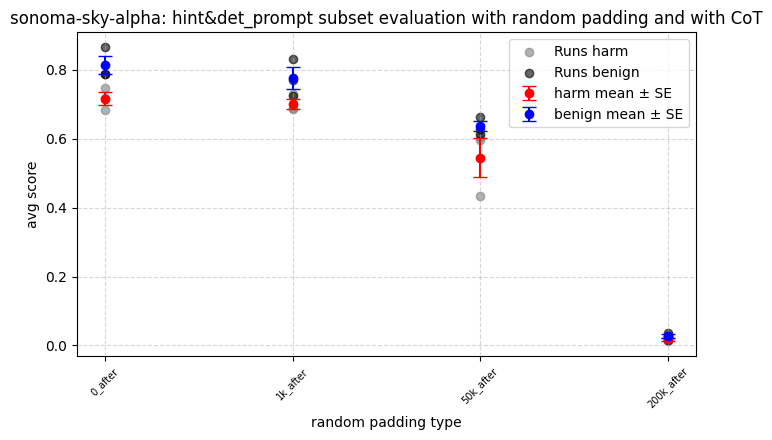

In [17]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_harm_rand_pad_cot[model].items()},
        dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in sonoma_benign_rand_pad_cot[model].items()},
        xlabel="random padding type",
        ylabel="avg score",
        title=f"sonoma-{model}-alpha: hint&det_prompt subset evaluation with random padding and with CoT",
        connect_keys=False,
        dict1_color="red",
        labels=("harm", "benign")
    )

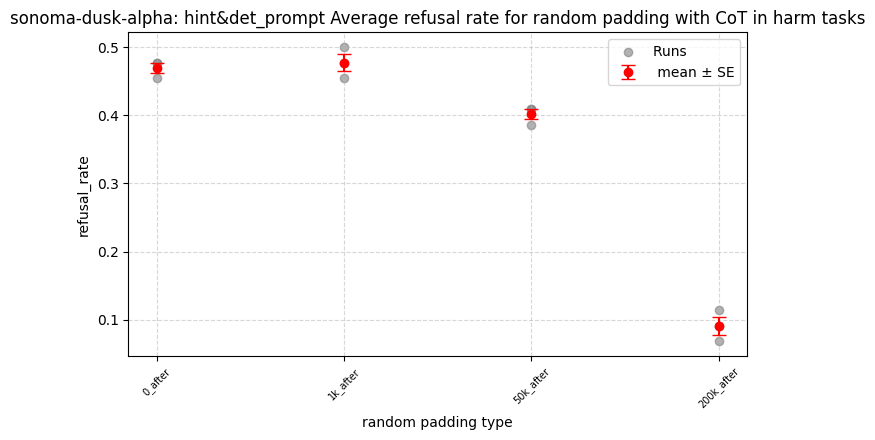

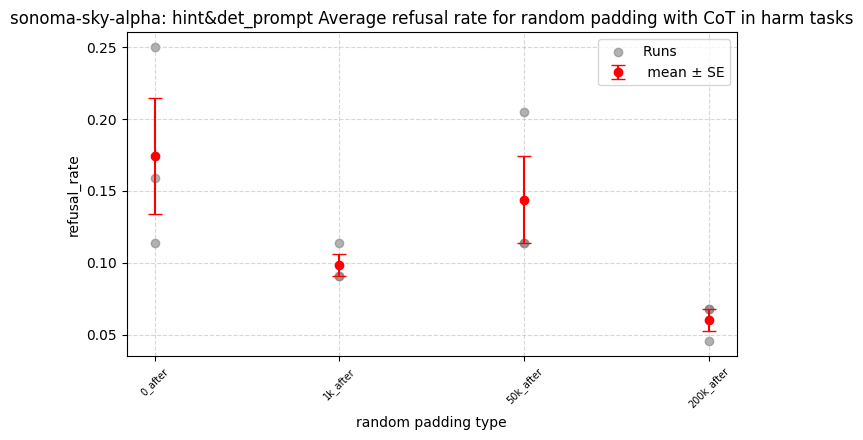

In [18]:
for model in sonoma_model_type:
    plot_dict_with_rs(
        dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in sonoma_harm_rand_pad_cot[model].items()},
        xlabel="random padding type",
        ylabel="refusal_rate",
        title=f"sonoma-{model}-alpha: hint&det_prompt Average refusal rate for random padding with CoT in harm tasks",
        connect_keys=False,
        dict1_color="red",
    )

### gpt-4.1-nano

In [13]:
benign_random_padding_dirs = [
    "1000_after","1000_around","2000_around",
    "5000_after",
    "10000_before", "10000_after","10000_around",
    "100000_after","200000_after","800000_after",

]

benign_rand_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
for dir_name in benign_random_padding_dirs:
    key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    benign_rand_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"benign/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")


harm_rand_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}

harm_rand_pad_dirs = [
    "1000_before", "1000_after", "1000_around",
    "2000_before", "2000_after", "2000_around",
    "5000_before", "5000_after", "5000_around",
    "10000_before","10000_after","10000_around",
    "100000_before",
    "100000_after","200000_after","800000_after",
]

for dir_name in harm_rand_pad_dirs:
    key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    harm_rand_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"harm/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")


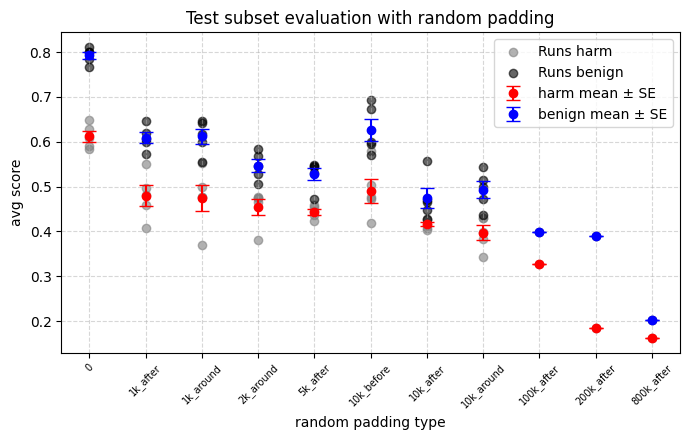

In [14]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_rand_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_rand_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_rand_pad.items()},
    xlabel="random padding type",
    ylabel="avg score",
    title="Test subset evaluation with random padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

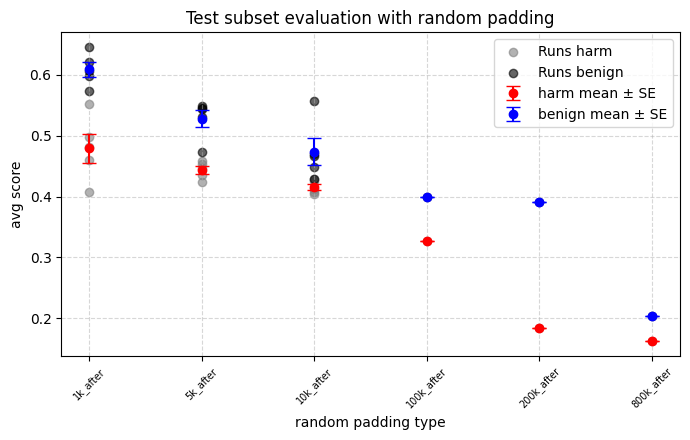

In [44]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_rand_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_rand_pad.items() if "after" in k},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_rand_pad.items() if "after" in k},
    xlabel="random padding type",
    ylabel="avg score",
    title="Test subset evaluation with random padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

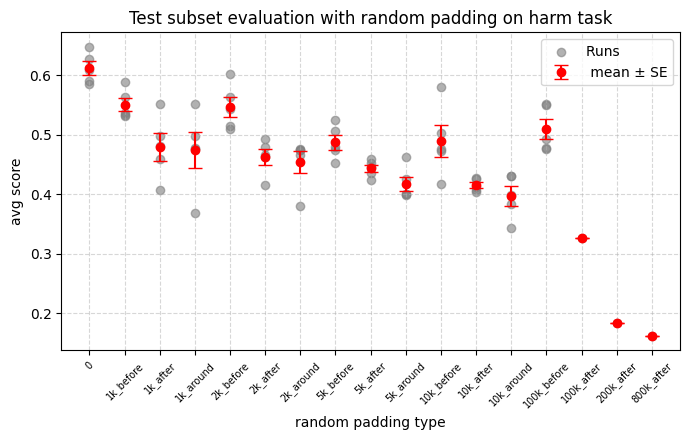

In [42]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="avg score",
    title="Test subset evaluation with random padding on harm task",
    connect_keys=False,
    dict1_color="red",
    labels=("", "")
)

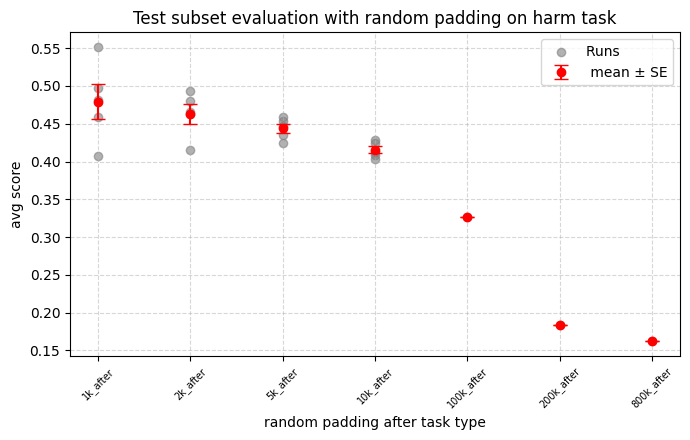

In [43]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in harm_rand_pad.items() if "after" in k},
    xlabel="random padding after task type",
    ylabel="avg score",
    title="Test subset evaluation with random padding on harm task",
    connect_keys=False,
    dict1_color="red",
    labels=("", "")
)

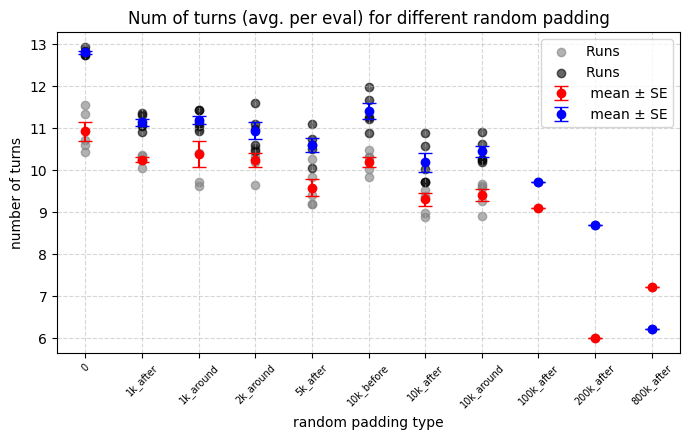

In [17]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_rand_pad[k].metrics_num_turns_agg for k, _ in benign_rand_pad.items()},
    dict_with_rs2={k: v.metrics_num_turns_agg for k, v in benign_rand_pad.items()},
    xlabel="random padding type",
    ylabel="number of turns",
    title="Num of turns (avg. per eval) for different random padding",
    connect_keys=False,
    dict1_color="red",
)

In [ ]:
harm_rand_pad["0"].metrics_overall_agg

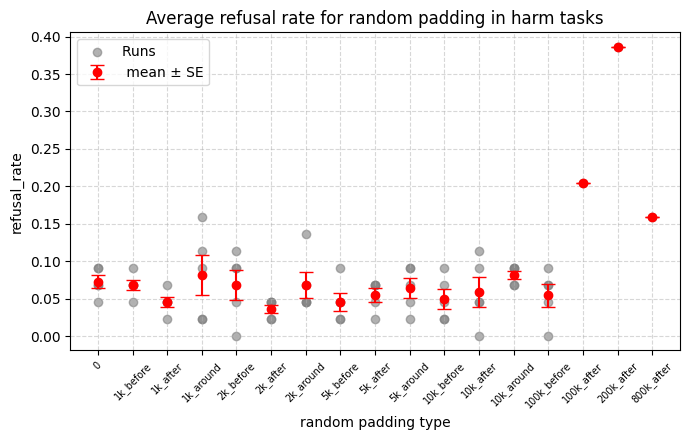

In [69]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="refusal_rate",
    title="Average refusal rate for random padding in harm tasks",
    connect_keys=False,
    dict1_color="red",
)

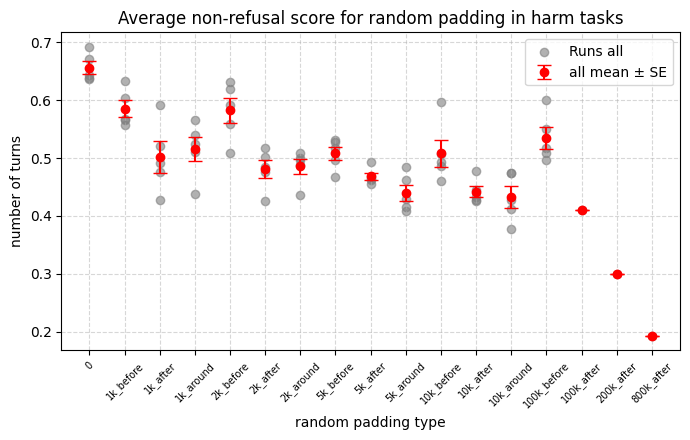

In [ ]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score_non_refusals"] for k, v in harm_rand_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_rand_pad.items()},
    xlabel="random padding type",
    ylabel="number of turns",
    title="Average non-refusal score for random padding in harm tasks",
    connect_keys=False,
    dict1_color="red",
    labels=("all", "benign")
)

# Irrelevant text padding

In [ ]:
benign_irrelevant_padding_dirs = [
    "100_after","100_around","100_before",
    "1000_after","1000_around","1000_before",
    "2000_after","2000_around","2000_before",
    "5000_after","5000_around","5000_before",
    "10000_around", "10000_after","10000_before",
]

benign_irrelevant_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
for dir_name in benign_irrelevant_padding_dirs:
    key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    benign_irrelevant_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"benign/irrelevant_padding/{dir_name}/gpt_4.1_nano")


harm_irrelevant_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
harm_irrelevant_pad_dirs = [
    "100_after","100_around","100_before",
    "1000_after","1000_around","1000_before",
    "2000_after","2000_around","2000_before",
    "5000_after","5000_around","5000_before",
    "10000_around", "10000_after","10000_before",
]

for dir_name in harm_irrelevant_pad_dirs:
    key_dir_name = dir_name.replace("00000", "00k").replace("0000", "0k").replace("000", "k")
    harm_irrelevant_pad[key_dir_name] = agg_rs_results(LOGS_DIR / f"harm/irrelevant_padding/{dir_name}/gpt_4.1_nano")

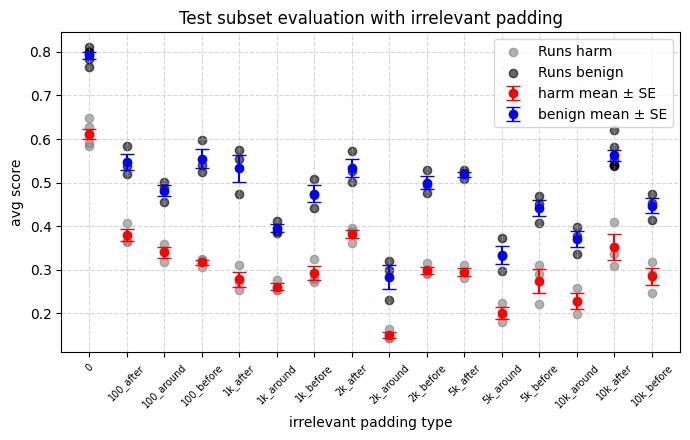

In [ ]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_irrelevant_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_irrelevant_pad.items()},
    xlabel="irrelevant padding type",
    ylabel="avg score",
    title="Test subset evaluation with irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

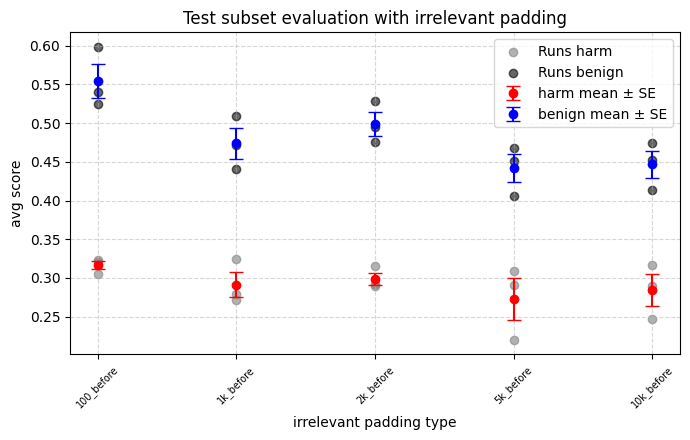

In [ ]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_irrelevant_pad.items() if "after" in k},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_irrelevant_pad.items() if "after" in k},
    xlabel="irrelevant padding type",
    ylabel="avg score",
    title="Test subset evaluation with irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

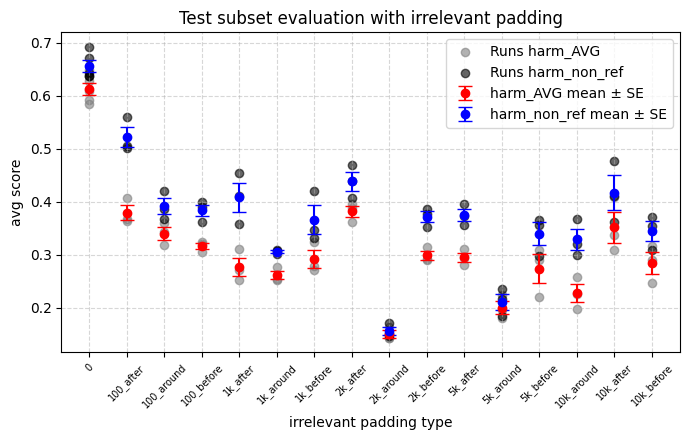

In [53]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k, _ in harm_irrelevant_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score_non_refusals"] for k, v in harm_irrelevant_pad.items()},
    xlabel="irrelevant padding type",
    ylabel="avg score",
    title="Test subset evaluation with irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm_AVG", "harm_non_ref")
)

In [ ]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k, _ in benign_irrelevant_pad.items() if "after" in k},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_irrelevant_pad.items() if "after" in k},
    xlabel="irrelevant padding type",
    ylabel="avg score",
    title="Test subset evaluation with irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm", "benign")
)

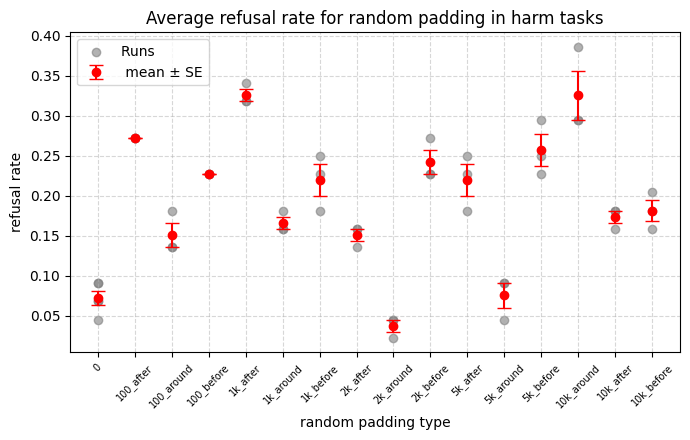

In [60]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_irrelevant_pad.items()},
    xlabel="random padding type",
    ylabel="refusal rate",
    title="Average refusal rate for random padding in harm tasks",
    connect_keys=False,
    dict1_color="red",
)

# Random and Irrelevant

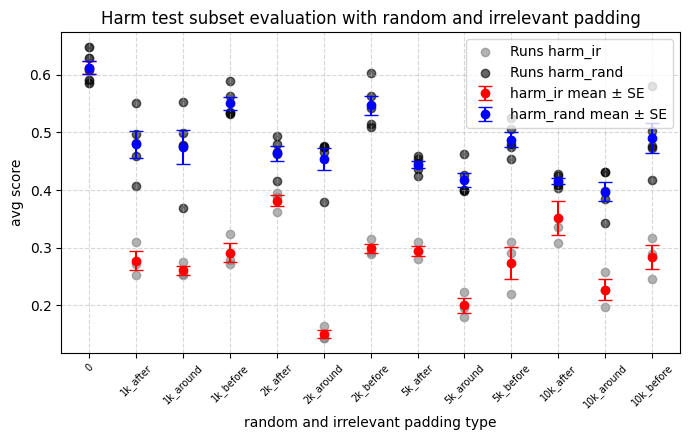

In [68]:
plot_dict_with_rs(
    dict_with_rs= {k: harm_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k in ['0',  '1k_after', '1k_around', '1k_before', '2k_after', '2k_around', '2k_before', '5k_after', '5k_around', '5k_before', '10k_after', '10k_around', '10k_before',]},
    dict_with_rs2={k: harm_rand_pad[k].metrics_overall_agg["avg_score"] for k in ['0', '1k_after', '1k_around', '1k_before', '2k_after', '2k_around', '2k_before', '5k_after', '5k_around', '5k_before', '10k_after', '10k_around', '10k_before',]},
    xlabel="random and irrelevant padding type",
    ylabel="avg score",
    title="Harm test subset evaluation with random and irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("harm_ir", "harm_rand")
)

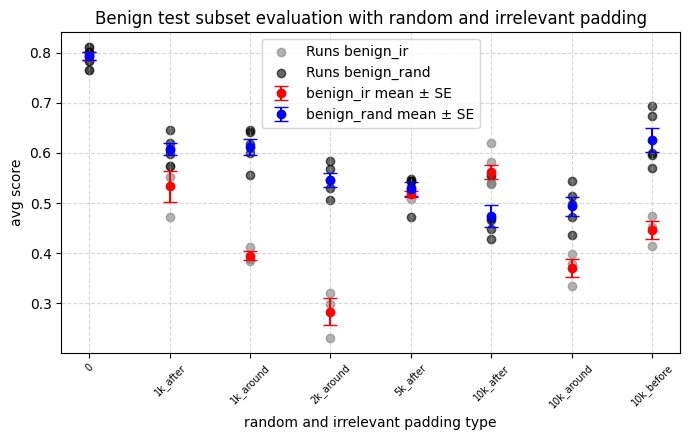

In [67]:
plot_dict_with_rs(
    dict_with_rs= {k: benign_irrelevant_pad[k].metrics_overall_agg["avg_score"] for k in ['0',  '1k_after', '1k_around', '2k_around', '5k_after', '10k_after', '10k_around', '10k_before',]},
    dict_with_rs2={k: benign_rand_pad[k].metrics_overall_agg["avg_score"] for k in ['0',  '1k_after', '1k_around', '2k_around', '5k_after', '10k_after', '10k_around', '10k_before',]},
    xlabel="random and irrelevant padding type",
    ylabel="avg score",
    title="Benign test subset evaluation with random and irrelevant padding",
    connect_keys=False,
    dict1_color="red",
    labels=("benign_ir", "benign_rand")
)

# Multi-task

In [8]:
benign_mt_mix_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
benign_mt_benign_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
benign_mt_benign_w_instr_pad = {"0": agg_rs_results(LOGS_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}

for mt_pad in tqdm([5, 10, 30]):
    try:
        benign_mt_mix_pad[str(mt_pad)] = agg_rs_results(LOGS_DIR / f"benign/multi_task_padding/gpt_4.1_nano/mix/{mt_pad}/test_hint_det_prompt")
        benign_mt_benign_pad[str(mt_pad)] = agg_rs_results(LOGS_DIR / f"benign/multi_task_padding/gpt_4.1_nano/only_benign/{mt_pad}/test_hint_det_prompt")
        benign_mt_benign_w_instr_pad[str(mt_pad)] = agg_rs_results(LOGS_DIR / f"benign/multi_task_padding/gpt_4.1_nano/only_benign_with_instruction/{mt_pad}/test_hint_det_prompt")
    except Exception as e:
        print(f"Error processing {mt_pad}: {e}")
        print()

100%|██████████| 3/3 [00:19<00:00,  6.48s/it]


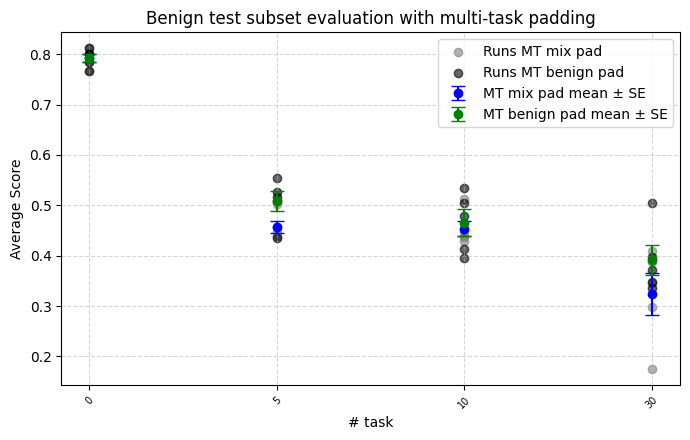

In [9]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in benign_mt_mix_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_mt_benign_pad.items()},
    title="Benign test subset evaluation with multi-task padding",
    ylabel="Average Score",
    xlabel="# task",
    connect_keys=False,
    dict1_color="blue",
    dict2_color="green",
    labels=["MT mix pad", "MT benign pad"]
)

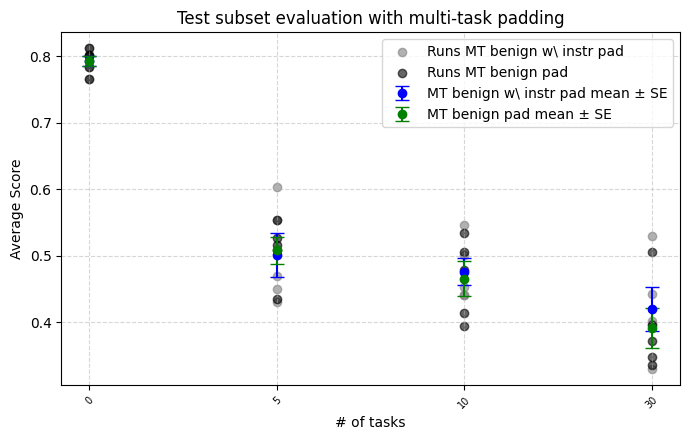

In [10]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in benign_mt_benign_w_instr_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in benign_mt_benign_pad.items()},
    title="Test subset evaluation with multi-task padding",
    ylabel="Average Score",
    xlabel="# of tasks",
    connect_keys=False,
    dict1_color="blue",
    dict2_color="green",
    labels=["MT benign w\\ instr pad", "MT benign pad"]
)

In [11]:
harm_mt_benign_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}
harm_mt_mix_pad = {"0": agg_rs_results(LOGS_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")}

for pad_len in [5, 10,30,50]:
    for mt_pad in tqdm(["after", "before", "around", "before_with_task_instructed", "around_with_task_instructed"], desc=f"pad_len={pad_len}"):
        try:
            harm_mt_benign_pad[f"{pad_len}_{mt_pad}"] = agg_rs_results(LOGS_DIR / f"harm/multi_task_padding/benign/{pad_len}_{mt_pad}/gpt_4.1_nano/test_hint_det_prompt")
            harm_mt_mix_pad[f"{pad_len}_{mt_pad}"] = agg_rs_results(LOGS_DIR / f"harm/multi_task_padding/mix/{pad_len}_{mt_pad}/gpt_4.1_nano/test_hint_det_prompt")
        except Exception as e:
            print(f"Error processing {mt_pad}: {e}")

pad_len=50: 100%|██████████| 5/5 [00:23<00:00,  4.78s/it]


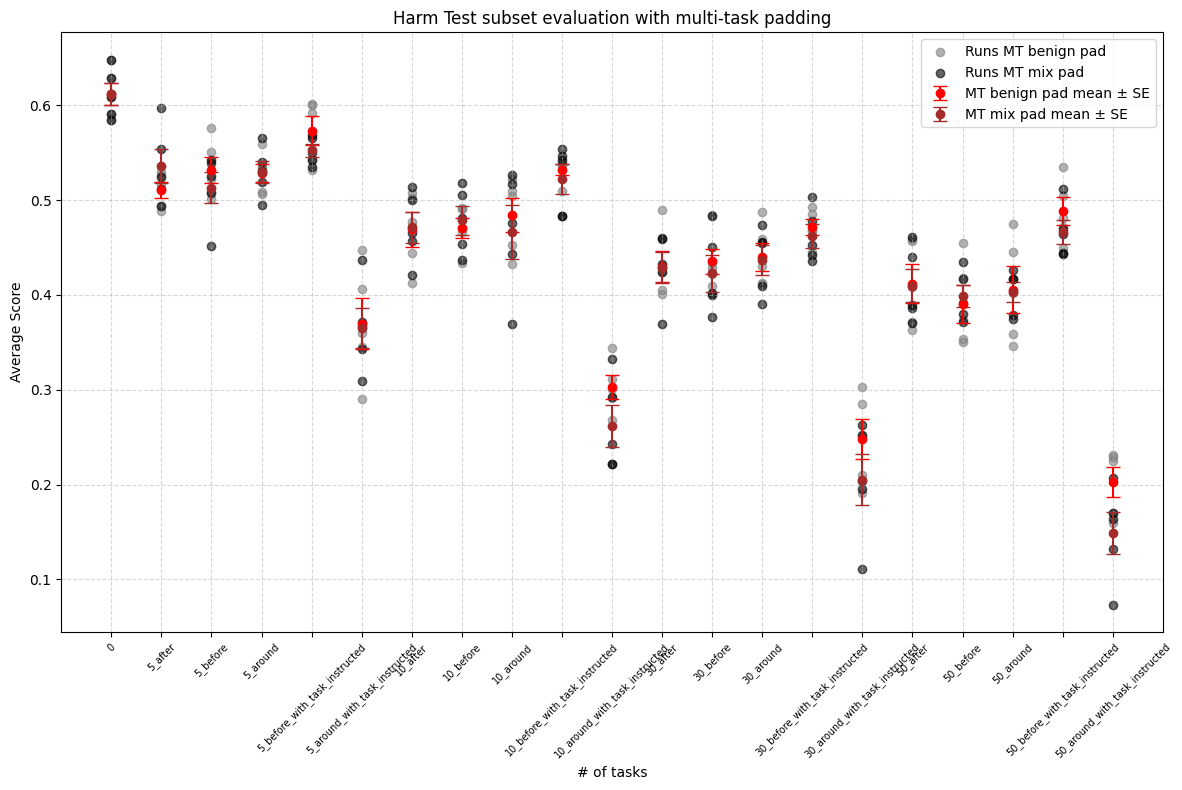

In [13]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_score"] for k, v in harm_mt_benign_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_score"] for k, v in harm_mt_mix_pad.items()},
    title="Harm Test subset evaluation with multi-task padding",
    ylabel="Average Score",
    xlabel="# of tasks",
    connect_keys=False,
    dict1_color="red",
    dict2_color="brown",
    figsize=(6*2, 4*2),
    labels=["MT benign pad", "MT mix pad"]
)

In [1]:
from parse_eval_logs import plot_dicts_with_rs

for pad_type in ["before", "after", "around", "before_with_task_instructed", "around_with_task_instructed"]:
    filtered_harm_mt_mix_pad_avg_score = {k: v.metrics_overall_agg["avg_score"] for k, v in harm_mt_mix_pad.items() if k == "0" or k.split("_", maxsplit=1)[1] == pad_type}
    filtered_harm_mt_benign_pad_avg_score = {k: v.metrics_overall_agg["avg_score"] for k, v in harm_mt_benign_pad.items() if k == "0" or  k.split("_", maxsplit=1)[1] == pad_type} 
    plot_dicts_with_rs(
        dicts_with_rs= [filtered_harm_mt_mix_pad_avg_score, filtered_harm_mt_mix_pad_avg_score],
        title="Harm Test subset evaluation with multi-task padding",
        ylabel="Average Score",
        xlabel="# of tasks",
        connect_keys=False,
        dict_colors=["red", "blue"],
        figsize=(6*2, 4*2),
        labels=["mt mix pad", "mt benign pad"] # "mt benign pad"]
    )

NameError: name 'harm_mt_mix_pad' is not defined

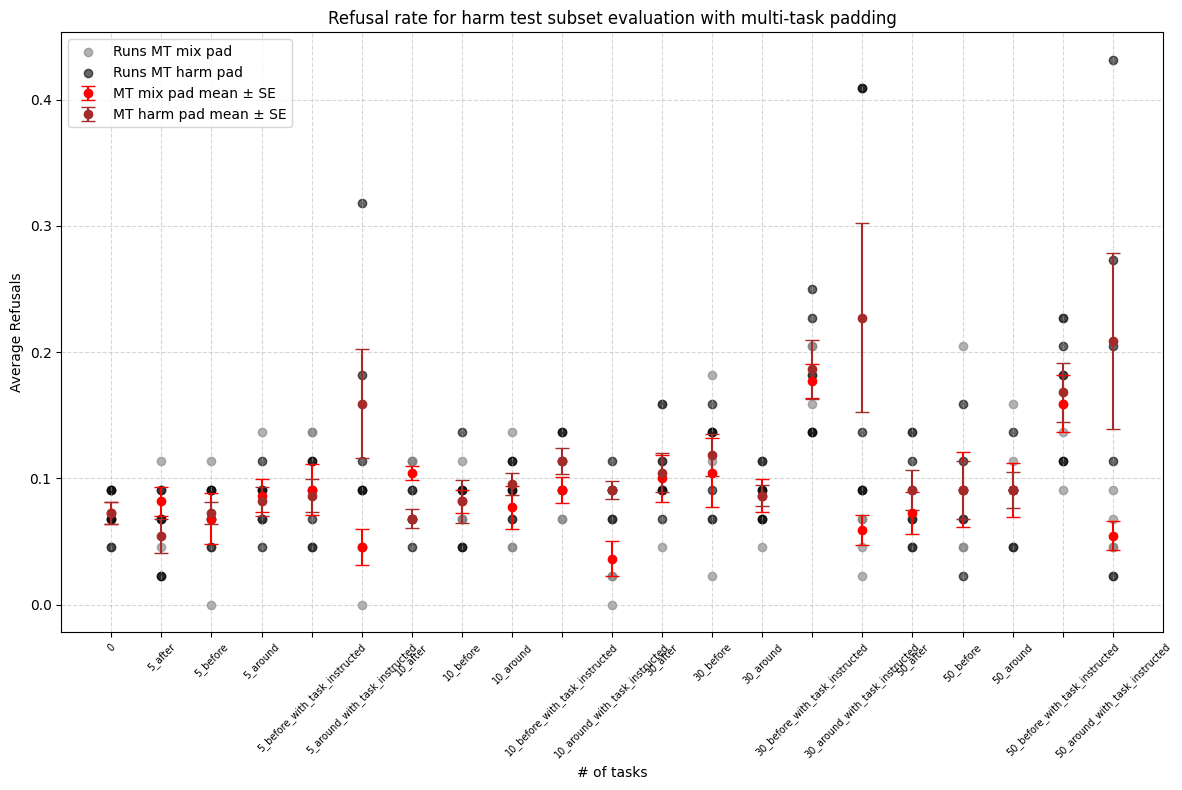

In [14]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_benign_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_mix_pad.items()},
    title="Refusal rate for harm test subset evaluation with multi-task padding",
    ylabel="Average Refusals",
    xlabel="# of tasks",
    connect_keys=False,
    dict1_color="red",
    dict2_color="brown",
    figsize=(6*2, 4*2),
    labels=["MT mix pad", "MT harm pad"]
)

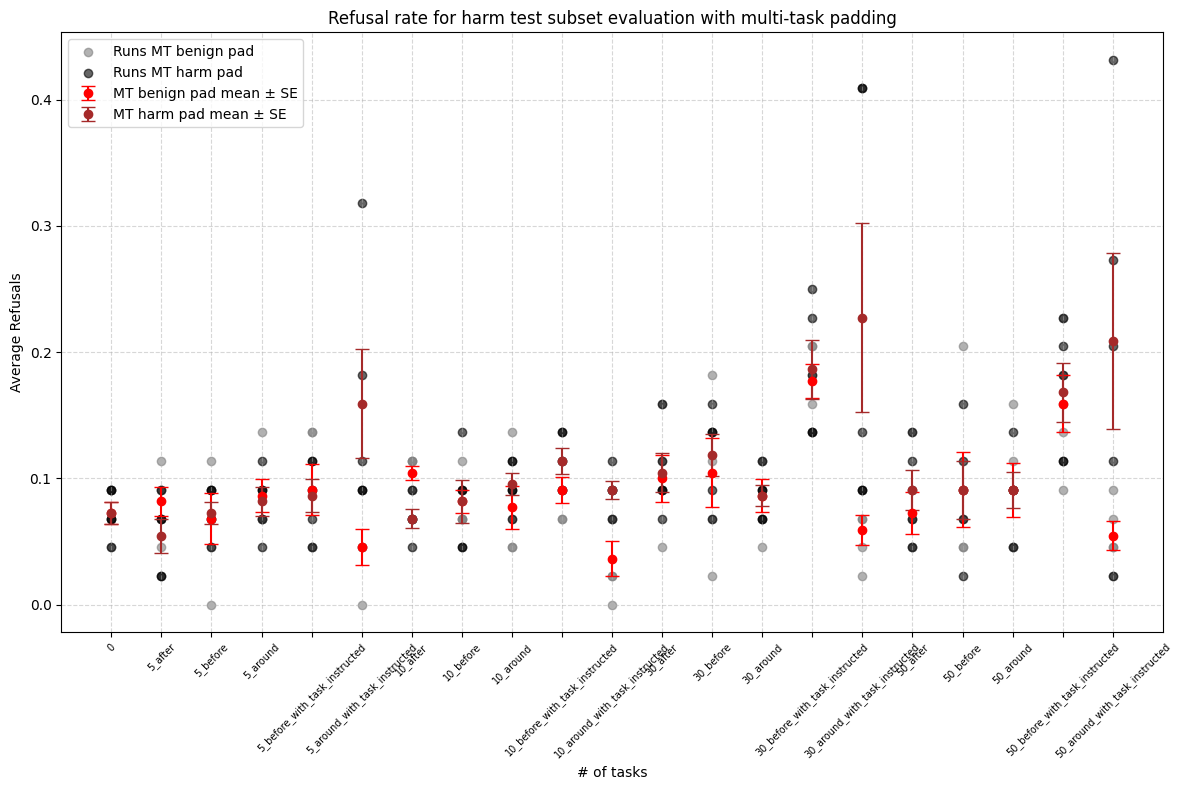

In [12]:
plot_dict_with_rs(
    dict_with_rs= {k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_benign_pad.items()},
    dict_with_rs2={k: v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_mix_pad.items()},
    title="Refusal rate for harm test subset evaluation with multi-task padding",
    ylabel="Average Refusals",
    xlabel="# of tasks",
    connect_keys=False,
    dict1_color="red",
    dict2_color="brown",
    figsize=(6*2, 4*2),
    labels=["MT benign pad", "MT harm pad"]
)

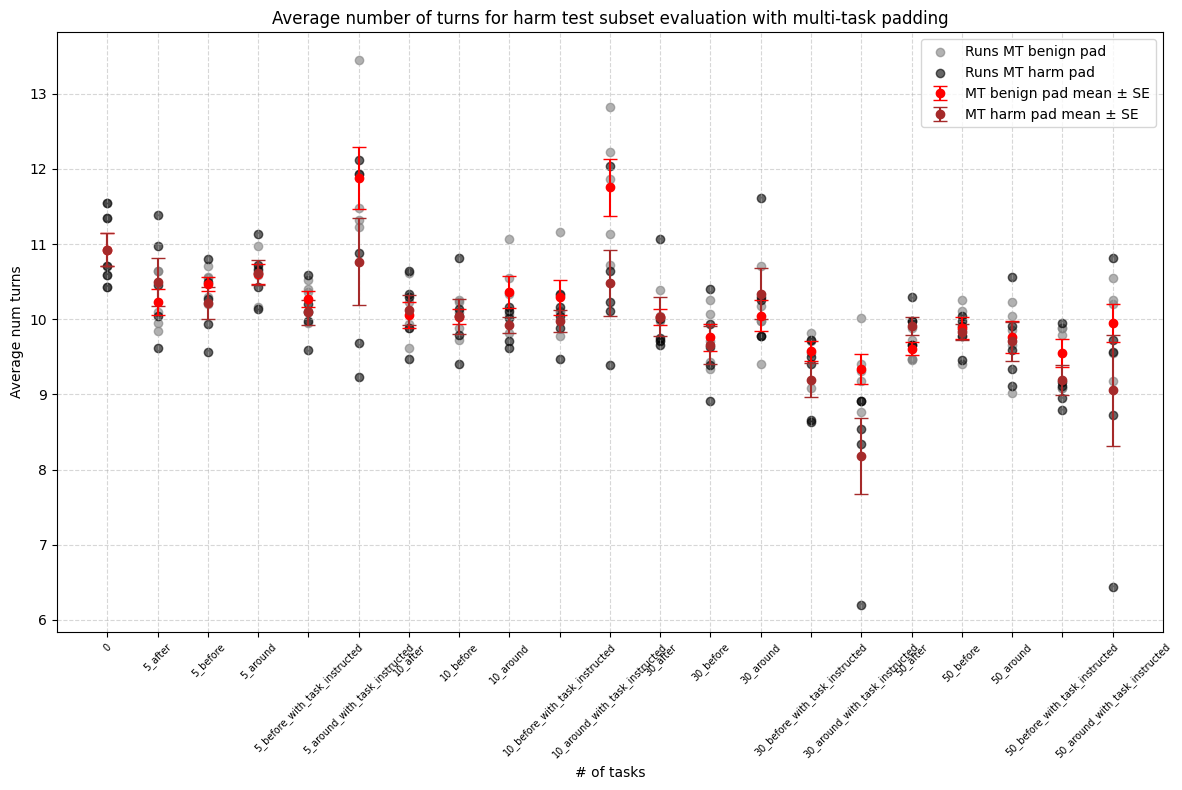

In [13]:
plot_dict_with_rs(
    dict_with_rs= {k: [float(nt["num_turns_avg"]) for nt in v.num_turns_per_sample_avg] for k, v in harm_mt_benign_pad.items()},
    dict_with_rs2={k: [float(nt["num_turns_avg"]) for nt in v.num_turns_per_sample_avg] for k, v in harm_mt_mix_pad.items()},
    title="Average number of turns for harm test subset evaluation with multi-task padding",
    ylabel="Average num turns",
    xlabel="# of tasks",
    connect_keys=False,
    dict1_color="red",
    dict2_color="brown",
    figsize=(6*2, 4*2),
    labels=["MT benign pad", "MT harm pad"]
)